# P5 Deteksi Tepi (Bagian 1 dan 2)
Format "# %%" dapat dibuka sebagai notebook (VS Code / Jupytext) atau disalin per sel ke Colab.

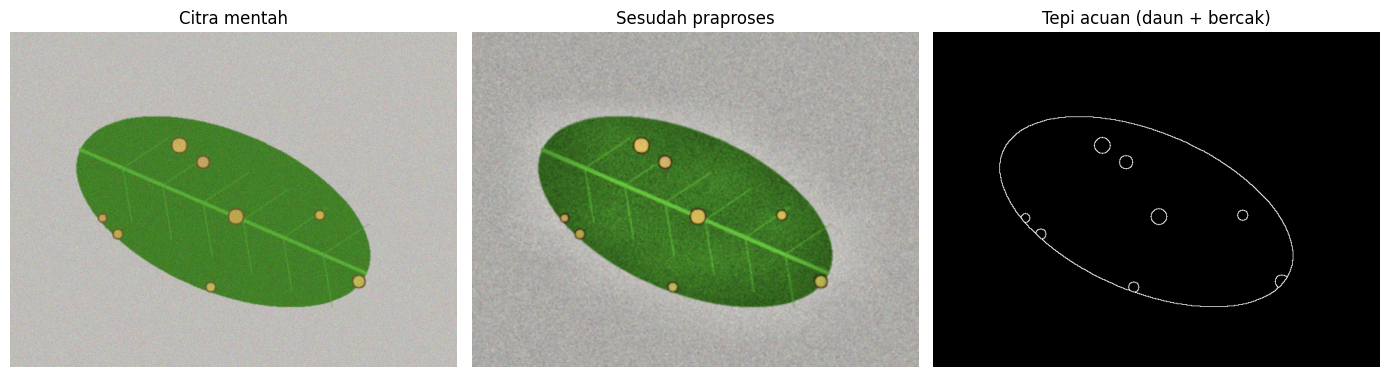

In [1]:
# Kode 1.1 Persiapan
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from utils_cv import baca, tampil
except ImportError:  # cadangan bila utils_cv belum ada
    def baca(path):
        return cv2.imread(path)

    def tampil(citra, judul, baris=1, ukuran=(14, 4)):
        kolom = int(np.ceil(len(citra) / baris))
        plt.figure(figsize=ukuran)
        for i, (c, j) in enumerate(zip(citra, judul)):
            plt.subplot(baris, kolom, i + 1)
            if c.ndim == 3:
                plt.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
            else:
                plt.imshow(c, cmap="gray")
            plt.title(j, fontsize=8); plt.axis("off")
        plt.show()
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")


def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb


img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

In [2]:
# Langkah 1.1 Verifikasi lembar hitung manual (hanya untuk mencocokkan hitungan tangan Anda)
A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], np.float32)
sobel_kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
prew_kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)

for nama, kx in [("Sobel", sobel_kx), ("Prewitt", prew_kx)]:
    Gx, Gy = float((A * kx).sum()), float((A * kx.T).sum())  # korelasi di piksel tengah
    print(f"{nama}: Gx={Gx:.0f} Gy={Gy:.0f} |G|={np.hypot(Gx, Gy):.2f} "
          f"|Gx|+|Gy|={abs(Gx) + abs(Gy):.0f} theta={np.degrees(np.arctan2(Gy, Gx)):.2f} deg "
          f"arah tepi={np.degrees(np.arctan2(Gy, Gx)) + 90:.2f} deg")
print("Laplacian pusat:", float((A * lap).sum()))

Sobel: Gx=534 Gy=22 |G|=534.45 |Gx|+|Gy|=556 theta=2.36 deg arah tepi=92.36 deg
Prewitt: Gx=399 Gy=17 |G|=399.36 |Gx|+|Gy|=416 theta=2.44 deg arah tepi=92.44 deg
Laplacian pusat: 118.0


selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 611.2


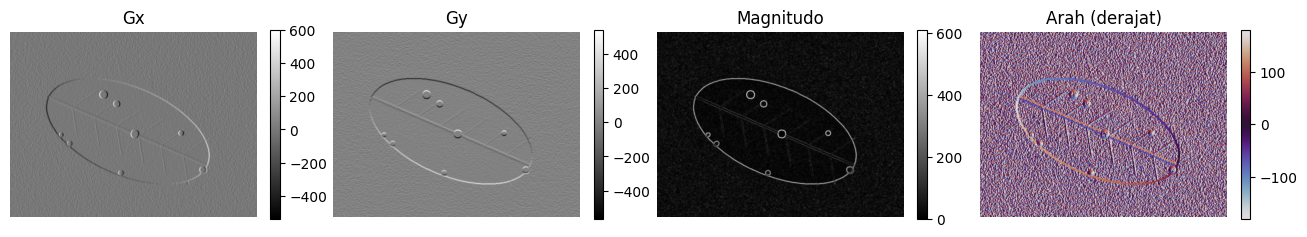

In [3]:
# Kode 1.2 Gradien Sobel manual
g = pra[:, :, 2].astype(np.float32)
kx = sobel_kx
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)
gy = cv2.filter2D(g, cv2.CV_32F, ky)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.show()

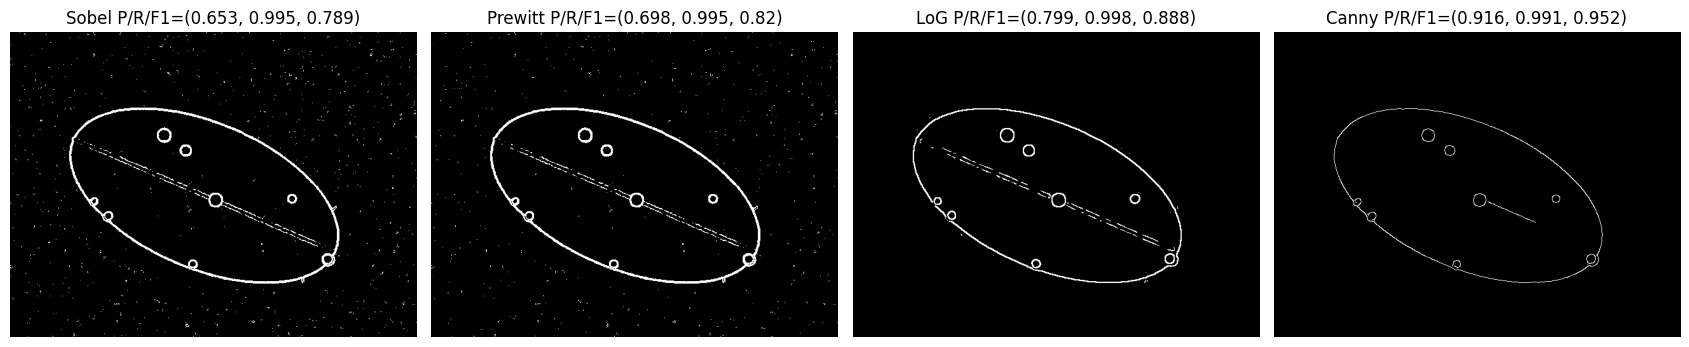

In [4]:
# Kode 1.3 Empat operator
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)


def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)


def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)


metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))

In [5]:
# Kode 1.4 Tabel presisi, recall, F1
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

# Tabel 6 (rerata F1) dalam format laporan
tabel6 = (tabel_tepi.groupby(["metode", "sumber", "kanal"]).F1.mean().round(3)
          .unstack(["sumber", "kanal"]).reindex(["Sobel", "Prewitt", "LoG", "Canny"]))
print(tabel6)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.750  0.748  0.747
                LoG      0.656  0.997  0.787
                Prewitt  0.802  0.962  0.866
                Sobel    0.771  0.969  0.847
          R     Canny    0.983  0.978  0.979
                LoG      0.907  0.997  0.944
                Prewitt  0.582  0.996  0.686
                Sobel    0.519  0.996  0.626
praproses Gray  Canny    0.684  0.954  0.788
                LoG      0.568  0.997  0.718
                Prewitt  0.562  0.996  0.709
                Sobel    0.529  0.996  0.678
          R     Canny    0.964  0.990  0.976
                LoG      0.846  0.997  0.907
                Prewitt  0.464  0.997  0.587
                Sobel    0.426  0.997  0.549
sumber  mentah        praproses       
kanal     Gray      R      Gray      R
metode                                
Sobel    0.847  0.626     0.678  0.549
Prewitt  0.866  0.686     0.709  0

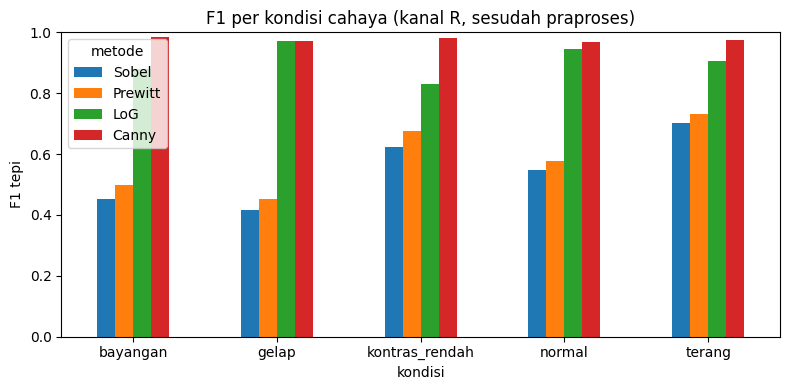

In [6]:
# Langkah 1.5 (Kerjakan sendiri) Grafik F1 per kondisi cahaya, kanal R sesudah praproses
sub = tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
pv = sub.pivot_table(index="kondisi", columns="metode", values="F1")[["Sobel", "Prewitt", "LoG", "Canny"]]
pv.plot(kind="bar", figsize=(8, 4))
plt.ylabel("F1 tepi"); plt.title("F1 per kondisi cahaya (kanal R, sesudah praproses)")
plt.xticks(rotation=0); plt.ylim(0, 1); plt.tight_layout()
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=150); plt.show()

In [7]:
# Langkah 2.1 Verifikasi lembar hitung NMS dan hysteresis
M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]])
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])


def nms_pusat(M, arah_deg):
    """Bandingkan piksel tengah dengan dua tetangga SEARAH GRADIEN (0 atau 90 derajat)."""
    a, b = (M[1, 0], M[1, 2]) if arah_deg == 0 else (M[0, 1], M[2, 1])
    return "dipertahankan" if M[1, 1] >= a and M[1, 1] >= b else "ditekan (0)"


for nm, M in [("M1", M1), ("M2", M2)]:
    print(nm, "arah 0:", nms_pusat(M, 0), "| arah 90:", nms_pusat(M, 90))


def hysteresis_1d(v, lo, hi):
    v = np.array(v)
    kuat, lemah = v >= hi, (v >= lo) & (v < hi)
    akhir = kuat.copy()
    berubah = True
    while berubah:  # lemah ikut jadi tepi bila bersebelahan dengan tepi
        berubah = False
        for i in range(len(v)):
            if lemah[i] and not akhir[i]:
                if (i > 0 and akhir[i - 1]) or (i < len(v) - 1 and akhir[i + 1]):
                    akhir[i] = True; berubah = True
    return kuat.astype(int), lemah.astype(int), akhir.astype(int)


k_, l_, a_ = hysteresis_1d([20, 60, 120, 80, 40, 90, 30], 50, 100)
print("kuat :", k_); print("lemah:", l_); print("akhir:", a_)

M1 arah 0: dipertahankan | arah 90: dipertahankan
M2 arah 0: ditekan (0) | arah 90: dipertahankan
kuat : [0 0 1 0 0 0 0]
lemah: [0 1 0 1 0 1 0]
akhir: [0 1 1 1 0 0 0]


In [8]:
# Kode 2.1 Eksperimen sigma dan ambang Canny
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    g = praproses(img, PARAM)[:, :, 2]
    ad, ab = tepi_acuan(md), tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print(canny.groupby(["sigma", "ambang"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
print(canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak").round(3))

                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.506  0.994  0.598     0.973
      30/90    0.021  0.998  0.041     0.992
      50/150   0.151  0.995  0.222     0.978
1.0   100/200  0.970  0.993  0.981     0.971
      30/90    0.266  0.994  0.357     0.975
      50/150   0.862  0.994  0.914     0.972
2.0   100/200  0.791  0.790  0.791     0.755
      30/90    0.964  0.990  0.976     0.957
      50/150   0.981  0.982  0.981     0.888
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.977   0.970
      30/90    0.993   0.992
      50/150   0.980   0.975
1.0   100/200  0.974   0.968
      30/90    0.977   0.973
      50/150   0.975   0.969
2.0   100/200  0.759   0.751
      30/90    0.957   0.958
      50/150   0.938   0.839


In [9]:
# Kode 2.2 Ambang Canny otomatis berbasis median
def canny_otomatis(g, s=0.33):
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        baris.append([d.kondisi_cahaya, kanal, "otomatis", skor_tepi(canny_otomatis(g), ac)[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kanal, "tetap 30/90", skor_tepi(tepi_canny(g), ac)[2], np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
print(auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))
print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.469  0.556           0.792   0.720   0.905
      tetap 30/90     0.768  0.738           0.936   0.736   0.763
R     otomatis        0.274  0.440           0.744   0.748   0.940
      tetap 30/90     0.985  0.972           0.982   0.970   0.974
kanal  kondisi       
Gray   bayangan          116.0
       gelap             136.1
       kontras_rendah    149.2
       normal            170.0
       terang            197.6
R      bayangan          125.0
       gelap             151.6
       kontras_rendah    150.8
       normal            177.4
       terang            199.1
Name: median, dtype: float64


In [10]:
# Langkah 2.4 (Kerjakan sendiri) Ambang Canny dari persentil magnitudo
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """(1) Gaussian, (2) magnitudo Sobel, (3) ambang atas = persentil ke-q, bawah = rasio x atas, (4) Canny."""
    gh = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    gf = gh.astype(np.float32)
    m = np.hypot(cv2.Sobel(gf, cv2.CV_32F, 1, 0), cv2.Sobel(gf, cv2.CV_32F, 0, 1))
    hi = float(np.percentile(m, q))
    lo = rasio * hi
    # L2gradient=True agar magnitudo Canny sama dengan hypot yang dipakai menghitung persentil
    return cv2.Canny(gh, lo, hi, L2gradient=True)


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        for q in [90, 95, 98]:
            baris.append([d.kondisi_cahaya, kanal, f"persentil {q}", skor_tepi(canny_persentil(g, q), ac)[2]])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1"])
print(pd.concat([auto[["kondisi", "kanal", "ambang", "F1"]], pers])
      .pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1").round(3))

kondisi             bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                       
Gray  otomatis         0.469  0.556           0.792   0.720   0.905
      persentil 90     0.082  0.078           0.069   0.083   0.080
      persentil 95     0.444  0.507           0.273   0.481   0.448
      persentil 98     0.780  0.816           0.746   0.785   0.810
      tetap 30/90      0.768  0.738           0.936   0.736   0.763
R     otomatis         0.274  0.440           0.744   0.748   0.940
      persentil 90     0.082  0.072           0.069   0.078   0.081
      persentil 95     0.357  0.185           0.228   0.457   0.457
      persentil 98     0.986  0.985           0.948   0.987   0.982
      tetap 30/90      0.985  0.972           0.982   0.970   0.974


kanal            Gray      R
kondisi                     
bayangan        827.0    0.0
gelap           858.2    0.0
kontras_rendah   53.5    0.0
normal          942.0    0.0
terang          848.5  209.0


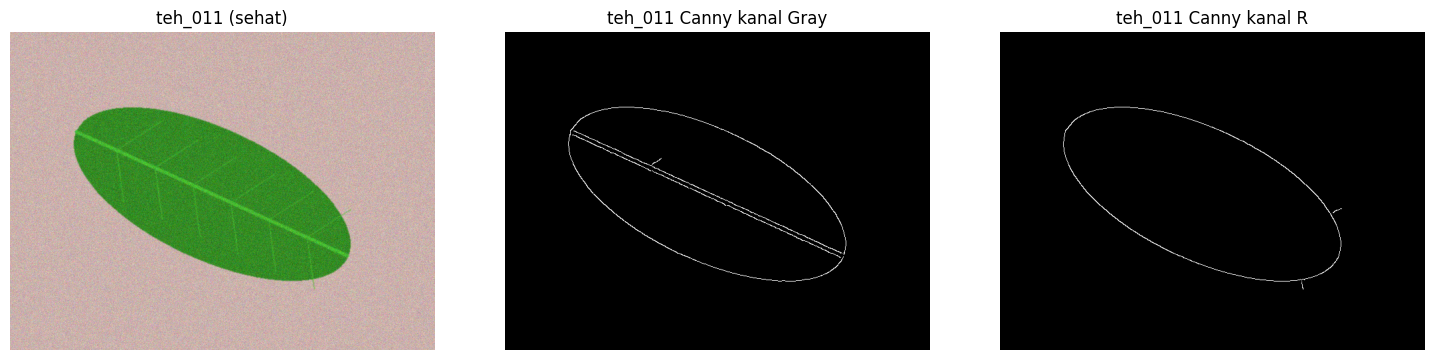

In [11]:
# Kode 2.3 Tepi palsu di dalam daun sehat
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0
    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)), ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
print(sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").round(1))
tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))

In [12]:
# Langkah 2.6 (Kerjakan sendiri) Tabel 8: kerangka keputusan, ISI SENDIRI berdasarkan bukti Anda
tabel8 = pd.DataFrame({
    "Keperluan": ["Menemukan batas daun", "Menemukan batas bercak",
                  "Mengisi wilayah bercak (segmentasi)", "Fitur bentuk bercak (P9)"],
    "Dipakai? (ya/tidak)": ["", "", "", ""],
    "Operator dan parameter": ["", "", "", ""],
    "Bukti (rujuk tabel/gambar)": ["", "", "", ""],
})
print(tabel8)

                             Keperluan Dipakai? (ya/tidak) Operator dan parameter Bukti (rujuk tabel/gambar)
0                 Menemukan batas daun                                                                      
1               Menemukan batas bercak                                                                      
2  Mengisi wilayah bercak (segmentasi)                                                                      
3             Fitur bentuk bercak (P9)                                                                      
